# Turning into Separation? — submission notebook starter

This first version reproduces input counts, season coverage and the prespecified receiver sample. It contains no new trait–performance associations or final submission claims.

Development uses 2023–24 rookie seasons; 2025 is reserved from further model development, although prior studies already analysed its outcomes. The eligibility figure is a draft for design review.

Run all cells. Local runs use cached Parquets or raw CSVs; Kaggle runs discover the four required competition CSVs. Only small aggregate tables enter pandas.

In [1]:
from pathlib import Path
import os
import duckdb
import matplotlib.pyplot as plt

required = ('players', 'combine_results', 'games', 'player_play')
override = os.environ.get('NFL_BDB_DATA_DIR')
if override:
    candidates = [Path(override)]
else:
    candidates = [Path('data/interim'), Path('../data/interim'), Path('data/raw'), Path('../data/raw')]
    kaggle = Path('/kaggle/input')
    if kaggle.exists():
        candidates = sorted({p.parent for p in kaggle.rglob('players.csv')})

matches = []
for directory in candidates:
    for extension in ('parquet', 'csv'):
        if all((directory / f'{name}.{extension}').exists() for name in required):
            matches.append((directory, extension))
if not matches:
    raise FileNotFoundError('Point NFL_BDB_DATA_DIR to the folder containing players, combine_results, games and player_play.')
if Path('/kaggle/input').exists() and not override and len(matches) != 1:
    raise ValueError('Multiple competition input folders found; set NFL_BDB_DATA_DIR explicitly.')
data_dir, extension = matches[0]
con = duckdb.connect()
con.execute("SET memory_limit='1GB'")
con.execute('SET threads=2')
for name in required:
    path = str((data_dir / f'{name}.{extension}').resolve()).replace("'", "''")
    reader = f"read_parquet('{path}')" if extension == 'parquet' else f"read_csv_auto('{path}', nullstr='NA')"
    con.execute(f'CREATE VIEW {name} AS SELECT * FROM {reader}')
print(f'Input format: {extension}; four required tables loaded as DuckDB views.')

Input format: parquet; four required tables loaded as DuckDB views.


## Input integrity and season coverage

A unique athlete key and unique game/play/athlete key prevent accidental row multiplication. Outcome analyses use REG only. The complete local audit also checks Combine and game-frame keys.

In [2]:
key_columns = {'players':'nfl_id', 'combine_results':'nfl_id', 'games':'game_id', 'player_play':'game_id, play_id, nfl_id'}
key_rows = []
for name, keys in key_columns.items():
    null_predicate = ' OR '.join(f'{key.strip()} IS NULL' for key in keys.split(','))
    row = con.execute(f"SELECT count(*), count(*) FILTER (WHERE {null_predicate}), count(*)-count(DISTINCT ROW({keys})) FROM {name}").fetchone()
    key_rows.append({'table':name, 'rows':row[0], 'null_keys':row[1], 'duplicate_rows':row[2]})
    assert row[1] == 0 and row[2] == 0, f'Invalid primary keys in {name}'
import pandas as pd
display(pd.DataFrame(key_rows))
season_counts = con.sql("""SELECT g.season_type, count(*) AS player_plays,
    count(DISTINCT pp.nfl_id) AS players FROM player_play pp JOIN games g USING(game_id)
    GROUP BY g.season_type ORDER BY g.season_type""").df()
display(season_counts)

,table,rows,null_keys,duplicate_rows
0,players,510,0,0
1,combine_results,510,0,0
2,games,1002,0,0
3,player_play,314197,0,0


,season_type,player_plays,players
0,POST,13169,161
1,PRE,51759,487
2,REG,249269,401


## Prespecified sample support

Count WRs with at least ten recorded separation plays on both pooled SLANT/OUT and GO, during their rookie REG season, excluding nullified plays. Eligibility uses outcome availability only.

Counts precede final feature checks and the measurement-reliability screen. They do not establish statistical power or a successful performance signal.

In [3]:
support = con.sql("""
WITH candidates AS (
    SELECT pp.nfl_id, p.draft_year,
        CASE WHEN pp.route_ran='GO' THEN 'GO' ELSE 'BREAK' END AS family
    FROM player_play pp JOIN players p USING(nfl_id)
    JOIN combine_results c USING(nfl_id) JOIN games g USING(game_id)
    WHERE c.combine_position='WR' AND g.season_type='REG'
      AND g.season=p.draft_year AND pp.play_nullified_by_penalty='N'
      AND pp.route_ran IN ('SLANT','OUT','GO')
      AND pp.separation_at_pass_forward IS NOT NULL
), family_counts AS (
    SELECT nfl_id, draft_year, family, count(*) AS n FROM candidates
    GROUP BY nfl_id, draft_year, family
), eligible AS (
    SELECT nfl_id, draft_year FROM family_counts WHERE n>=10
    GROUP BY nfl_id, draft_year HAVING count(*)=2
), totals AS (
    SELECT p.draft_year, count(*) AS combine_WRs
    FROM players p JOIN combine_results c USING(nfl_id)
    WHERE c.combine_position='WR' GROUP BY p.draft_year
), selected AS (
    SELECT draft_year, count(*) AS eligible_WRs FROM eligible GROUP BY draft_year
)
SELECT t.draft_year, t.combine_WRs, coalesce(s.eligible_WRs,0) AS eligible_WRs
FROM totals t LEFT JOIN selected s USING(draft_year) ORDER BY t.draft_year
""").df()
display(support)
print('Development eligible WRs:', int(support.loc[support.draft_year.isin([2023,2024]), 'eligible_WRs'].sum()))
print('Evaluation eligible WRs:', int(support.loc[support.draft_year == 2025, 'eligible_WRs'].sum()))

,draft_year,combine_WRs,eligible_WRs
0,2023,39,25
1,2024,31,17
2,2025,37,16


Development eligible WRs: 42
Evaluation eligible WRs: 16


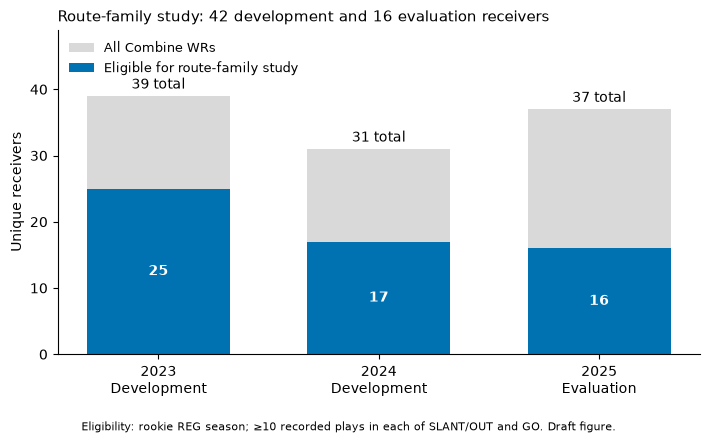

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
x = list(range(len(support)))
ax.bar(x, support.combine_WRs, width=.65, color='#D9D9D9', label='All Combine WRs')
ax.bar(x, support.eligible_WRs, width=.65, color='#0072B2', label='Eligible for route-family study')
for i, row in enumerate(support.itertuples(index=False)):
    ax.text(i, row.eligible_WRs / 2, str(row.eligible_WRs), ha='center', va='center', color='white', fontweight='bold')
    ax.text(i, row.combine_WRs + .6, f'{row.combine_WRs} total', ha='center', va='bottom', fontsize=10)
ax.set_xticks(x, [f'{year}\n' + ('Development' if year < 2025 else 'Evaluation') for year in support.draft_year])
ax.set_ylabel('Unique receivers')
development_n = int(support.loc[support.draft_year.isin([2023,2024]), 'eligible_WRs'].sum())
evaluation_n = int(support.loc[support.draft_year == 2025, 'eligible_WRs'].sum())
ax.set_title(f'Route-family study: {development_n} development and {evaluation_n} evaluation receivers', loc='left', fontsize=11)
ax.set_ylim(0, max(support.combine_WRs) + 10)
ax.spines[['top','right']].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.text(.12, .01, 'Eligibility: rookie REG season; ≥10 recorded plays in each of SLANT/OUT and GO. Draft figure.', fontsize=8)
fig.tight_layout(rect=[0,.05,1,1])
out = Path('reports/figures')
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / 'study3_support.png', dpi=200, bbox_inches='tight')
plt.show()
con.close()

## Next additions

1. Reproduced movement reliability and documented join attrition.
2. Measurement screen and frozen training-only preprocessing.
3. Audited baseline versus tracking evaluation, with player-aware intervals.
4. Final football interpretation and supporting figures.

This starter is not ready for publication or submission.